# Proyecto Programación y Paradigmas para Ciencia de Datos.


**Alumno:** Torres Jimenez Edgar Iván


## Conjunto de datos elegido: 
### IBM HR Analytics Employee Attrition & Performance

La traducción al español del nombre del Dataset sería: "IBM Recursos Humanos Rendimiento y deserción de los empleados".
Link de descarga: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

In [1]:
enlace = 'https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset'

## Descripción del dataset

En el dataset contamos con 35 columnas, y más de 1400 datos de distintos empleados, las caracteristicas que definen a cada empleado son relacionadas a lo laboral, económico y familiar.

La finalidad es poder predecir si un empleado va a dejar su puesto de trabajo o permanecerá en la compañia.

## CRISP-DM, a modo de recordatorio durante el proyecto:

1. Entendimiento del negocio
2. Entendimiento de los datos (puede retornarnos al primer paso)
3. preparación de los datos
4. Modelado (puede regresarnos al paso anterior)
5. Evaluación (dependiendo el resultado, si falla es probable que tengamos que regresar hasta el primer paso)
6. Puesta en operación [deployment]
7. 

## CRISP-DM: Etapa 1:
### ¿Por qué es importante saber si un empleado renunciará ó no?

Podemos decir que para una compañía los empleados son parte fundamental de sus "recursos", el caso de IBM que es una empresa reconocida en el mundo de la técnología y es muy reconocida por cualquiera que se dedique se quiera dedicar a ésta área, entonces si decimos que los empleados son parte fundamental de una compañía, queremos que los empleados se desarrollen de la mejor manera en el desarrollo de sus actividades, ya que de ello depende su rendimeinto, y ese rendimiento se traduce en ganancias para la empresa.

Cuando tenemos a mucha gente renunciando o siendo despedida, tenemos un problema de alta rotación del personal, al ser IBM una empresa de tamaño transnacional, requiere que esos puestos de trabajo no se queden vacíos, si no no podría cumplir sus objetivos como empresa.

Algunos de los inconvenientes de la alta rotación del personal son:

1. Cuesta mucho dinero y tiempo el proceso de selección, contratación y capacitación de nuevos empleados.
2. Los trabajadores que ya contaban con experiencia, ya no están en la empresa, entones tenemos una especie de "fuga de experiencia".
3. Perdidas en la productividad
4. Perdidas en las ganancias.


Ya teniendo un contexto de los datos que vamos a analizar, su importancia y porqué es importante buscar un modelo para el problema, vamos a hacer un análisis a los datos.

### Importación de bibliotecas

- NumPy permitirá realizar operaciones matemáticas.

- Pandas permitirá cargar y manipular el dataset.

- Matplotlib y Seaborn se utilizarán para el análisis exploratorio.

- RANDOM_STATE será una semilla fija para que las particiones y los experimentos aleatorios puedan reproducirse.

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
# Para Preprocesamiento (Estandarización  y Encoding)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, precision_recall_curve, PrecisionRecallDisplay,
                             ConfusionMatrixDisplay)

from sklearn.tree import DecisionTreeClassifier, plot_tree


RANDOM_STATE = 42

### Cargar los datos
Desde nuestro directorio ../data/ buscamos el archivo csv que descargamos del repositorio de Kaggle.


In [3]:
df = pd.read_csv('./data/WA_Fn-UseC_-HR-Employee-Attrition.csv')

### Inspección inicial del dataset

Para esta inspección vamos a anlizar el tamaño del datset, los tipos de datos, la cantidad de datos nulos y duplicados

**Tamaño del dataset:**
- El dataset contiene 1 470 empleados (filas) y 35 columnas.
- 26 columnas son numéricas y 9 son de texto (categóricas), incluida la variable objetivo **Attrition**.

**No hay valores nulos**: no hace falta imputar nada.

**No hay filas duplicadas**: cada fila es un empleado distinto.

**Columnas que no aportan información**
- EmployeeCount (siempre 1)
- Over18 (siempre "Y")
- StandardHours (siempre 80)
- EmployeeNumber es un identificador (un valor distinto por fila).


In [4]:
df.head(5).T

,0,1,2,3,4
Age,41,49,37,33,27
Attrition,Yes,No,Yes,No,No
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373,1392,591
Department,Sales,Research & Development,Research & Development,Research & Development,Research & Development
DistanceFromHome,1,8,2,3,2
Education,2,1,2,4,1
EducationField,Life Sciences,Life Sciences,Other,Life Sciences,Medical
EmployeeCount,1,1,1,1,1
EmployeeNumber,1,2,4,5,7


In [5]:
df.shape

(1470, 35)

In [6]:
# COnteo de nulos
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
# Verificamos si tenemos duplicados
df.duplicated().sum()

np.int64(0)

In [9]:
df["EmployeeCount"].unique() 
# Esto nos deja ver que sólo tiene un valor esta columana.

array([1])

In [10]:
df["Over18"].unique() 


<StringArray>
['Y']
Length: 1, dtype: str

In [11]:
df["StandardHours"].unique() 


array([80])

In [12]:
df.describe().T

# EL agregar el metodo T, hace que se  transponga la matriz, y nos permite ver todo, ya que de forma normal Jupyter nos omite información

# Si podemos apreciar alguna variable con desviación = 0, entonces probablemente sea una constante

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


#### Eliminiación de variables que no aportan información.



In [13]:
constantes = df.nunique()[df.nunique() == 1].index.tolist()
identificadores = df.nunique()[df.nunique() == len(df)].index.tolist()
df = df.drop(columns=constantes + identificadores)

In [14]:
df.shape

(1470, 31)

#### Separamos en nuestras variables (X) y la variable objetivo (y).

Nuestra variable objetivo como ya lo había mencionado al principio de este notebook es la variable Atrition (deserción).

In [15]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

In [16]:
y.head()

0    Yes
1     No
2    Yes
3     No
4     No
Name: Attrition, dtype: str

In [17]:
X.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,3,1,0,8,0,1,6,4,0,5
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,4,4,1,10,3,3,10,7,1,7
2,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,...,3,2,0,7,3,3,0,0,0,0
3,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,...,3,3,0,8,3,3,8,7,3,0
4,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,...,3,4,1,6,3,3,2,2,2,2


In [18]:
X.shape #Comprobamos las nuevas dimensiones
# 30 Variables

(1470, 30)

### Variable objetivo

La variable objetivo viene como texto ("Yes" / "No"). Para poder usarla en los modelos la convertimos a número: **1 = el empleado se va** y **0 = el empleado se queda**.

In [19]:
y = y.map({"No": 0, "Yes": 1})
y.value_counts()
#y.shape
#y.value_counts()/(y.shape[0])*100
#y.shape

Attrition
0    1233
1     237
Name: count, dtype: int64

Tasa de deserción: 16.12%


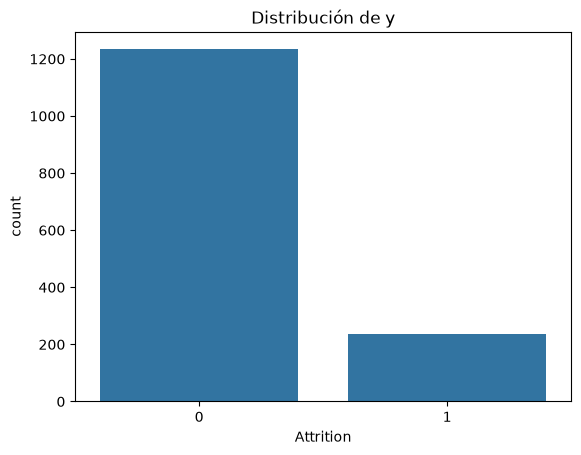

In [20]:
print(f"Tasa de deserción: {y.mean():.2%}")

sns.countplot(x=y)
plt.xticks([0, 1])
plt.title("Distribución de y")
plt.show()

Solo alrededor del 16% de los empleados se va, es decir, tenemos que la variable objetivo está desbalanceada. Esto es importante porque un modelo que siempre prediga "se queda" ya acertaría cerca del 84 %, así que la exactitud (accuracy) por sí sola engaña y por ende no sería la métrica ideal. Por eso más adelante usaremos también recall, F1 y compararemos todos los modelos.


### Tipos de variables

Separamos las variables en tres grupos porque cada una se analiza de forma distinta:

- **Categóricas:** son las de texto.
- **Numéricas discretas:** tienen pocos valores distintos (niveles de satisfacción del 1 al 4, años, etc.).
- **Numéricas continuas:** tienen muchos valores distintos (edad, ingreso mensual, etc.).


In [25]:
resumen = pd.DataFrame({
    "tipo_dato": X.dtypes.astype(str),
    "n_unicos": X.nunique(),
})

# Mínimo y máximo solo de las columnas numéricas (en las de texto quedan como NaN)
resumen["minimo"] = X.min(numeric_only=True)
resumen["maximo"] = X.max(numeric_only=True)

# Ordenamos por tipo de dato y luego por cantidad de valores únicos
resumen = resumen.sort_values(["tipo_dato", "n_unicos"])
resumen

,tipo_dato,n_unicos,minimo,maximo
PerformanceRating,int64,2,3.0,4.0
EnvironmentSatisfaction,int64,4,1.0,4.0
JobInvolvement,int64,4,1.0,4.0
JobSatisfaction,int64,4,1.0,4.0
RelationshipSatisfaction,int64,4,1.0,4.0
StockOptionLevel,int64,4,0.0,3.0
WorkLifeBalance,int64,4,1.0,4.0
Education,int64,5,1.0,5.0
JobLevel,int64,5,1.0,5.0
TrainingTimesLastYear,int64,7,0.0,6.0


In [27]:
for col in X.columns:
    valores = sorted(X[col].unique().tolist())
    if len(valores) <= 10:
        print(f"{col} ({len(valores)} únicos): {valores}")
    else:
        print(f"{col} ({len(valores)} únicos): de {valores[0]} a {valores[-1]}, ej. {valores[:5]} +")

Age (43 únicos): de 18 a 60, ej. [18, 19, 20, 21, 22] +
BusinessTravel (3 únicos): ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
DailyRate (886 únicos): de 102 a 1499, ej. [102, 103, 104, 105, 106] +
Department (3 únicos): ['Human Resources', 'Research & Development', 'Sales']
DistanceFromHome (29 únicos): de 1 a 29, ej. [1, 2, 3, 4, 5] +
Education (5 únicos): [1, 2, 3, 4, 5]
EducationField (6 únicos): ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
EnvironmentSatisfaction (4 únicos): [1, 2, 3, 4]
Gender (2 únicos): ['Female', 'Male']
HourlyRate (71 únicos): de 30 a 100, ej. [30, 31, 32, 33, 34] +
JobInvolvement (4 únicos): [1, 2, 3, 4]
JobLevel (5 únicos): [1, 2, 3, 4, 5]
JobRole (9 únicos): ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
JobSatisfaction (4 únicos): [1, 2, 3, 4]
MaritalStat

## Variables Ordinales

En el repositorio desde donde squé el dataset, se incluye esta especie de Diccionario de datos, y nos indica el significado de estás variables categóricas, que son más ordinales

Education
1 'Below College'
2 'College'
3 'Bachelor'
4 'Master'
5 'Doctor'

EnvironmentSatisfaction
1 'Low'
2 'Medium'
3 'High'
4 'Very High'

JobInvolvement
1 'Low'
2 'Medium'
3 'High'
4 'Very High'

JobSatisfaction
1 'Low'
2 'Medium'
3 'High'
4 'Very High'

PerformanceRating
1 'Low'
2 'Good'
3 'Excellent'
4 'Outstanding'

RelationshipSatisfaction
1 'Low'
2 'Medium'
3 'High'
4 'Very High'

WorkLifeBalance
1 'Bad'
2 'Good'
3 'Better'
4 'Best'

In [21]:
# Variables categóricas (texto)
cat_cols = []
cat_cols.append("BusinessTravel") # frecuencia de viajes de trabajo
cat_cols.append("Department") # departamento
cat_cols.append("EducationField") # área de estudios
cat_cols.append("Gender")  # género
cat_cols.append("JobRole") # puesto
cat_cols.append("MaritalStatus") # estado civil
cat_cols.append("OverTime") # ¿ hace horas extra?

# Variables numéricas discretas (pocos valores distintos)
disc_cols = []
disc_cols.append("DistanceFromHome") # distancia a casa
disc_cols.append("Education") # nivel de estudios (1 a 5)
disc_cols.append("EnvironmentSatisfaction") # satisfacción con el ambiente (1 a 4)
disc_cols.append("JobInvolvement") # involucramiento en el trabajo (1 a 4)
disc_cols.append("JobLevel") # nivel del puesto (1 a 5)
disc_cols.append("JobSatisfaction") # satisfacción con el puesto (1 a 4)
disc_cols.append("NumCompaniesWorked") # empresas donde ha trabajado
disc_cols.append("PercentSalaryHike") # porcentaje de aumento de sueldo
disc_cols.append("PerformanceRating") # evaluación de desempeño
disc_cols.append("RelationshipSatisfaction")# satisfacción con las relaciones (1 a 4)
disc_cols.append("StockOptionLevel") # nivel de opciones de acciones (0 a 3)
disc_cols.append("TrainingTimesLastYear") # capacitaciones el año pasado
disc_cols.append("WorkLifeBalance") # balance vida-trabajo (1 a 4)
disc_cols.append("YearsInCurrentRole") # años en el puesto actual
disc_cols.append("YearsSinceLastPromotion") # años desde el último ascenso
disc_cols.append("YearsWithCurrManager") # años con el mismo jefe

# Variables numéricas continuas
cont_cols = []
cont_cols.append("Age") # edad
cont_cols.append("DailyRate") # tarifa diaria
cont_cols.append("HourlyRate") # tarifa por hora
cont_cols.append("MonthlyIncome") # ingreso mensual
cont_cols.append("MonthlyRate") # tarifa mensual
cont_cols.append("TotalWorkingYears") # años totales trabajados
cont_cols.append("YearsAtCompany") # años en la empresa

# Las numéricas son las discretas más las continuas
num_cols = disc_cols + cont_cols


In [22]:
df[cont_cols]

,Age,DailyRate,HourlyRate,MonthlyIncome,MonthlyRate,TotalWorkingYears,YearsAtCompany
0,41,1102,94,5993,19479,8,6
1,49,279,61,5130,24907,10,10
2,37,1373,92,2090,2396,7,0
3,33,1392,56,2909,23159,8,8
4,27,591,40,3468,16632,6,2
...,...,...,...,...,...,...,...
1465,36,884,41,2571,12290,17,5
1466,39,613,42,9991,21457,9,7
1467,27,155,87,6142,5174,6,6
1468,49,1023,63,5390,13243,17,9


In [23]:
df[cat_cols]

,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
0,Travel_Rarely,Sales,Life Sciences,Female,Sales Executive,Single,Yes
1,Travel_Frequently,Research & Development,Life Sciences,Male,Research Scientist,Married,No
2,Travel_Rarely,Research & Development,Other,Male,Laboratory Technician,Single,Yes
3,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Married,Yes
4,Travel_Rarely,Research & Development,Medical,Male,Laboratory Technician,Married,No
...,...,...,...,...,...,...,...
1465,Travel_Frequently,Research & Development,Medical,Male,Laboratory Technician,Married,No
1466,Travel_Rarely,Research & Development,Medical,Male,Healthcare Representative,Married,No
1467,Travel_Rarely,Research & Development,Life Sciences,Male,Manufacturing Director,Married,Yes
1468,Travel_Frequently,Sales,Medical,Male,Sales Executive,Married,No


Ya que tenemos una idea de cómo están los datos, ya hicimos la diferenciación entre datos categóricos y numéricos continuos y discretos, procedemos con nuestra siguiente etapa de CRISP-DM.

### Etapa 3: Preparación de los datos,

#### Partición en entrenamiento y prueba

Dividimos los datos en 80 % para entrenamiento y 20 % para prueba. Usamos stratify=y para que ambos conjuntos mantengan la misma proporción de renuncias (aprox. 16 %); con clases desbalanceadas esto es importante, si no podría quedar casi sin bajas alguno de los dos conjuntos.

El conjunto de prueba no se vuelve a tocar hasta la etapa de evaluación, para evitar Data Leakage.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
) #No olvidar importar la librería

In [36]:
# Verificamos porqué es importante usar Stratify
print("Porcentaje train", y_train.mean()*100)
print("Porcentaje test", y_test.mean()*100)


Porcentaje train 16.156462585034014
Porcentaje test 15.98639455782313


### Preprocesamiento

Los modelos no pueden trabajar con texto ni con variables en escalas muy distintas (K-NN, la red neuronal, PCA y la regresión son sensibles a esto), así que:

- **Numéricas:** imputamos con la mediana (por seguridad, aunque no hay nulos, aunque también sirve por si más adelante se proporcionan datos ) y estandarizamos.
- **Categóricas:** imputamos con la moda y aplicamos One-Hot Encoding. Usamos esta codificación y no números del 1 al N porque estos últimos inventarían un orden entre categorías que no existe (por ejemplo, que "Sales" sea mayor que "Human Resources"), y al final son puestos, para los fines de este análisis no tienen esa "ordinalidad".
- Las variables ordinales (satisfacción del 1 al 4, "JobLevel", etc.) se quedan como números, porque su orden sí tiene sentido.

Todo esto lo metemos en un ColumnTransformer que luego será el primer paso de cada Pipeline. De esta forma, durante la validación cruzada la estandarización y la codificación se aprenden solo con los datos de entrenamiento de cada partición, y evitamos fuga de información (data leakage).

In [37]:
def preprocesador():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

In [42]:
prep_demo = preprocesador().fit(X_train)
Z_train = prep_demo.transform(X_train)
nombres_vars = prep_demo.get_feature_names_out()
print("Antes:", X_train.shape, "| Después:", Z_train.shape)
nombres_vars

Antes: (1176, 30) | Después: (1176, 51)


array(['num__DistanceFromHome', 'num__Education',
       'num__EnvironmentSatisfaction', 'num__JobInvolvement',
       'num__JobLevel', 'num__JobSatisfaction', 'num__NumCompaniesWorked',
       'num__PercentSalaryHike', 'num__PerformanceRating',
       'num__RelationshipSatisfaction', 'num__StockOptionLevel',
       'num__TrainingTimesLastYear', 'num__WorkLifeBalance',
       'num__YearsInCurrentRole', 'num__YearsSinceLastPromotion',
       'num__YearsWithCurrManager', 'num__Age', 'num__DailyRate',
       'num__HourlyRate', 'num__MonthlyIncome', 'num__MonthlyRate',
       'num__TotalWorkingYears', 'num__YearsAtCompany',
       'cat__BusinessTravel_Non-Travel',
       'cat__BusinessTravel_Travel_Frequently',
       'cat__BusinessTravel_Travel_Rarely',
       'cat__Department_Human Resources',
       'cat__Department_Research & Development', 'cat__Department_Sales',
       'cat__EducationField_Human Resources',
       'cat__EducationField_Life Sciences',
       'cat__EducationField_Marke

El resultado de la anterior celda nos muestra cómo es ue queda nuestro dataframe ya procesado, el usar el pipeline nos ayuda a que sea un proceso más general y que en caso de que el dataset crecierá ó los datos mutarán, no habría cambios mayores al código.

Una vez teniendo datos ya preprocesados, ahora pasamos a la siguiente parte de CRISP-DM

## CRISP-DM: Etapa 4: Modelado

Dado que la misión del dataset es muy evidente y ya está lo suficientemente documentada en internet, me gustaría probar los distintos modelos vistos en el semestre, con la finalidad de ver cómo aplicarlos, qué ventajas nos ofrecen y cuáles son sus limitaciones.

Dividimos el modelado en dos partes:

1. **Aprendizaje no supervisado** (PCA y K-means): no usa la variable objetivo para formar los grupos, nos sirve para entender la estructura de los empleados.
2. **Aprendizaje supervisado**  K-NN, ANN y árbol de decisión: predice si un empleado se va, afinado con GridSearch y validación cruzada.

### Aprendizaje no supervisado

#### PCA (Análisis de Componentes Principales)

Después del One-Hot tenemos muchas variables, varias de ellas redundantes. PCA las resume en componentes (combinaciones de las variables originales) ordenados por la varianza que explican. Primero vemos cuántos componentes necesitamos para conservar el 90 % de la información.

También me parece importante aclarar que PCA no es un modelo clasificador, sólo nos ayuda pra reducir la dimensionalidad de los datos.

Componentes necesarios para el 90 % de la varianza: 23 (de 51 variables)


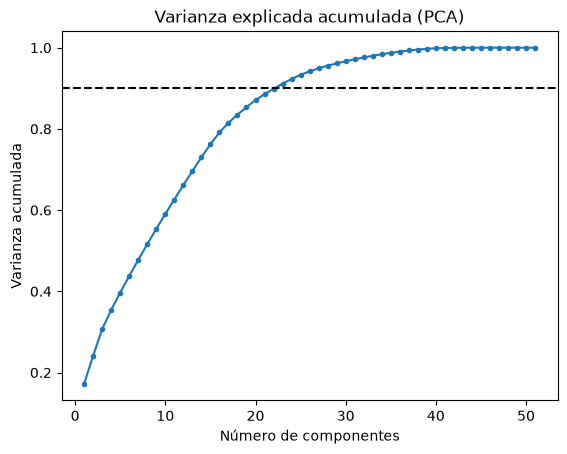

In [44]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE).fit(Z_train)
var_acum = np.cumsum(pca.explained_variance_ratio_) #Calculamos la varianza representada acumulada con n componentes 
n_90 = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes necesarios para el 90 % de la varianza: {n_90} (de {Z_train.shape[1]} variables)")

plt.plot(range(1, len(var_acum) + 1), var_acum, marker=".")
plt.axhline(0.90, color="k", ls="--")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada (PCA)")
plt.show()

Una de las cosas para la que usamos PCA en clase fue para poder graficar la información con dimensión mayor a dos, vamos a hacer lo mismo aquí, aunque observando la gráfica de la Varianza explicada acumulada, nos daremos cuenta que con dos componentes logramos representar aproximadamente 25 % de la varianza.

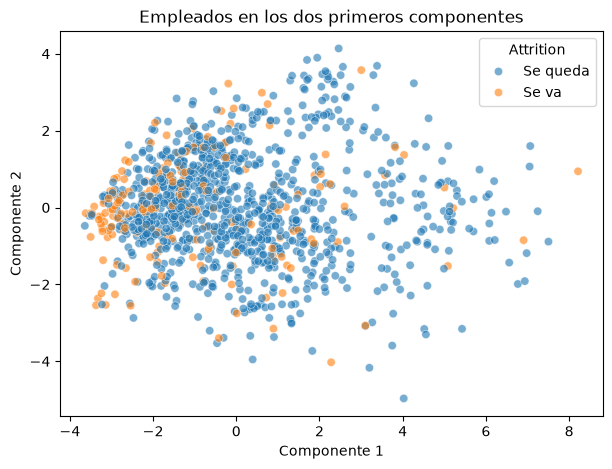

In [45]:
Z_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z_train)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=Z_2d[:, 0], y=Z_2d[:, 1], hue=y_train.map({0: "Se queda", 1: "Se va"}), alpha=0.6)
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.title("Empleados en los dos primeros componentes")
plt.show()

Dada la poca varianza explicada por dos componeentes, y la naturaleza de los datos no podemos apreciar agrupaciones claras usando PCA, digo esto sólo es a priori y a puro criterio personal.

#### K-means (K-medias0)

Agrupa a los empleados en **K segmentos** parecidos entre sí. Trabajamos con los componentes de PCA que explican el 90 % de la varianza (menos ruido, menos dimensiones y nos sirve para demostrar la utilidad del PCA). Para elegir K usamos:

- **Método del codo** (inercia): buscamos el punto donde la mejora deja de ser grande.

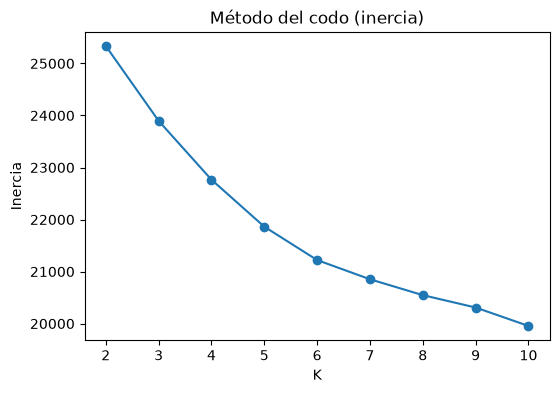

In [54]:
from sklearn.cluster import KMeans

Z_pca = PCA(n_components=n_90, random_state=RANDOM_STATE).fit_transform(Z_train)

ks = range(2, 11)
inercias = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_pca)
    inercias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ks, inercias, marker="o")
ax.set_title("Método del codo (inercia)")
ax.set_xlabel("K")
ax.set_ylabel("Inercia")
plt.show()

In [55]:
K = 4   # elegimos K con base en las dos gráficas anteriores
etiquetas_km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_pca)

In [57]:
# Aquí describimos cada "agrupación" (centroide), y lo asociamos con su tasa de deserción. [Después añadí las variables represntativas]
seg = X_train.copy()
seg["Attrition"] = y_train
seg["km"] = etiquetas_km

seg.groupby("km").agg(
    n=("Attrition", "size"),
    tasa_desercion=("Attrition", "mean"),
    edad=("Age", "mean"),
    ingreso=("MonthlyIncome", "mean"),
    nivel_puesto=("JobLevel", "mean"),
    antiguedad=("YearsAtCompany", "mean"),
)

,n,tasa_desercion,edad,ingreso,nivel_puesto,antiguedad
km,,,,,,
0,176,0.079545,48.426136,15263.642045,4.034091,14.357955
1,161,0.192547,36.024845,5258.950311,1.795031,6.031056
2,279,0.100358,36.032258,6242.225806,2.107527,10.315412
3,560,0.208929,34.167857,4323.392857,1.526786,3.419643


Aquí termina la sección de modelos de aprendizaje no supervisado, usé los que vimos en clase, de igual forma el dataset está pensado para aprendizaje supervisado ya que contamos con la variable objetivo.

### Aprendizaje supervisado

#### Métricas de evaluación

La siguiente tabla nos servirá como guía para ver porqué elegí una u otra métrica, respecto a acurracy sabemos que no sería ideal usarla, dado que tenemos que la variale objetivo está desbalanceada.

| Métrica | Pregunta que responde |
|---|---|
| **Recall** | De los que realmente se fueron, ¿a cuántos detectamos? |
| **Precision** | De los que marcamos como "se van", ¿cuántos se fueron de verdad? |
| **F1** | Equilibrio entre precision y recall |
| **Accuracy** | Solo de referencia, se compara contra la línea base |

También comparamos la exactitud en entrenamiento contra la de prueba para detectar sobreajuste (nuestro modelo  está memorizando datos).

Escribimos una sola función de evaluación que usaremos con todos los modelos, para no repetir el mismo código. Guarda las métricas en un diccionario que usaremos después para comparar. 

Puntuaciones es la probabilidad de que el empleado se vaya.

In [59]:
resultados = {}   # nombre del modelo - métricas
modelos = {}      # nombre del modelo - modelo entrenado

def puntuaciones(modelo, X_):
    # Devuelve la probabilidad de que el empleado se vaya
    return modelo.predict_proba(X_)[:, 1]

def evaluar(modelo, nombre, score_cv=np.nan):
    pred_tr = modelo.predict(X_train)
    pred_te = modelo.predict(X_test)

    resultados[nombre] = {
        "score_cv": score_cv,
        "acc_train": accuracy_score(y_train, pred_tr),
        "acc_test": accuracy_score(y_test, pred_te),
        "precision": precision_score(y_test, pred_te, zero_division=0),
        "recall": recall_score(y_test, pred_te),
        "f1": f1_score(y_test, pred_te),
    }
    modelos[nombre] = modelo

    r = resultados[nombre]
    print(f"===== {nombre} =====")
    print(f"Accuracy  train: {r['acc_train']:.3f} | prueba: {r['acc_test']:.3f}")
    print(f"Precision: {r['precision']:.3f} | Recall: {r['recall']:.3f} | F1: {r['f1']:.3f}")
    print(pd.DataFrame(confusion_matrix(y_test, pred_te),
                       index=["real: queda", "real: va"], columns=["pred: queda", "pred: va"]))

#### GridSearch y validación cruzada

Para cada modelo seguimos la misma receta:

1. Definimos un Pipeline (preprocesamiento, modelo, y a veces PCA o SFS).
2. Definimos una rejilla de hiperparámetros a probar.
3. GridSearchCV prueba todas las combinaciones con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento: en cada vuelta entrena con 4 partes y valida con la restante.
4. Nos quedamos con la combinación de mejor puntaje promedio y la evaluamos una sola vez con el conjunto de prueba.

Usamos F1 como criterio de selección porque, con clases desbalanceadas, premia a los modelos que detectan a quienes se van sin marcar a demasiados empleados que no se van.

In [60]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Función para aplicar GridSeach y CV, y nos devuelve la evaluación
def ajustar(nombre, pipe, rejilla):
    gs = GridSearchCV(pipe, rejilla, scoring="f1", cv=cv)
    gs.fit(X_train, y_train)
    print("Mejores parámetros:", gs.best_params_)
    print(f"f1 en validación cruzada: {gs.best_score_:.3f}")
    print()
    evaluar(gs.best_estimator_, nombre, score_cv=gs.best_score_)
    return gs

#### K-NN (K vecinos más cercanos)

Predice mirando a los K empleados más parecidos del entrenamiento y tomando la clase mayoritaria entre ellos. Por eso es importante haber estandarizado antes las variables: si no, las de mayor escala dominarían la distancia. Ajustamos:

- n_neighbors: cuántos vecinos se consultan (pocos = modelo más sensible al ruido).
- weights: si todos los vecinos pesan igual o los más cercanos pesan más.
- pca: reducir dimensiones suele ayudar a K-NN, porque las distancias se vuelven poco informativas con muchas variables. (Idea tomada de: https://www.geeksforgeeks.org/machine-learning/k-nearest-neighbors-and-curse-of-dimensionality/)

In [66]:
pipe_knn = Pipeline([
    ("prep", preprocesador()),
    ("pca", "inter"),
    ("clf", KNeighborsClassifier()),
])

rejilla_knn = {
    "pca": ["inter", PCA(n_components=0.90)],
    "clf__n_neighbors": [5, 7, 11, 25, 31], # sqrt(53)=7
    "clf__weights": ["uniform", "distance"],
}

gs_knn = ajustar("K-NN", pipe_knn, rejilla_knn)

Mejores parámetros: {'clf__n_neighbors': 5, 'clf__weights': 'uniform', 'pca': PCA(n_components=0.9)}
f1 en validación cruzada: 0.204

===== K-NN =====
Accuracy  train: 0.871 | prueba: 0.844
Precision: 0.533 | Recall: 0.170 | F1: 0.258
             pred: queda  pred: va
real: queda          240         7
real: va              39         8


/home/razumikhin/Documents/ciencia_de_datos/2027-1/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:489: FitFailedWarning: 
50 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "/home/razumikhin/Documents/ciencia_de_datos/2027-1/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/razumikhin/Documents/ciencia_de_datos/2027-1/.venv/lib/python3.13/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args,

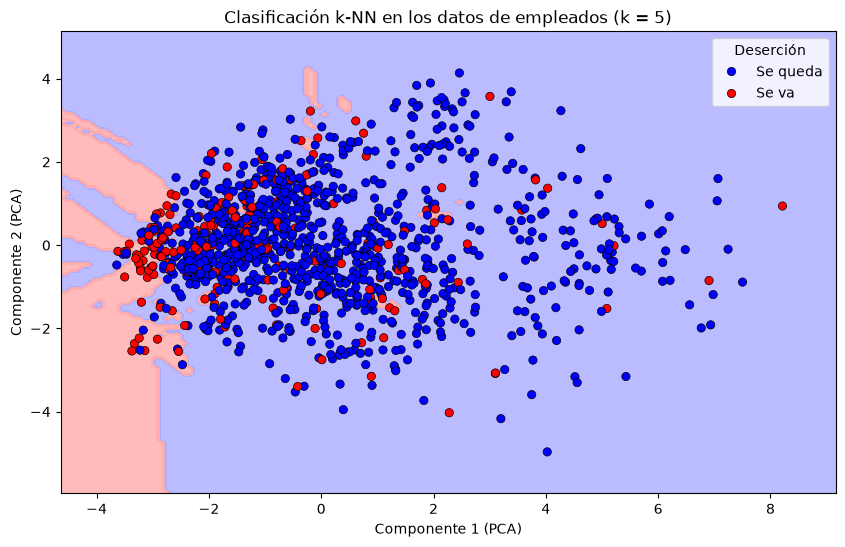

In [73]:
from matplotlib.colors import ListedColormap

# K-NN con los mejores K y pesos de GridSearch, entrenado solo con los 2 primeros componentes de PCA
k_vecinos = gs_knn.best_params_["clf__n_neighbors"]
knn_2d = KNeighborsClassifier(n_neighbors=k_vecinos,
                              weights=gs_knn.best_params_["clf__weights"]).fit(Z_2d, y_train)

# Malla de puntos que cubre todo el plano
h = 0.1
x_min, x_max = Z_2d[:, 0].min() - 1, Z_2d[:, 0].max() + 1
y_min, y_max = Z_2d[:, 1].min() - 1, Z_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predecimos la clase de cada punto de la malla
y_predict = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Visualización
plt.figure(figsize=(10, 6))
cmap_light = ListedColormap(['#AAAAFF', '#FFAAAA'])
cmap_bold = ['blue', 'red']
nombres_clase = y_train.map({0: "Se queda", 1: "Se va"})

# Pintar las áreas de decisión de fondo
plt.contourf(xx, yy, y_predict, cmap=cmap_light, alpha=0.8)

# Dibujar los puntos reales del dataset encima
sns.scatterplot(
    x=Z_2d[:, 0],
    y=Z_2d[:, 1],
    hue=nombres_clase,
    hue_order=["Se queda", "Se va"],
    palette=cmap_bold,
    alpha=1.0,
    edgecolor="black"
)

plt.title(f"Clasificación k-NN en los datos de empleados (k = {k_vecinos})")
plt.xlabel("Componente 1 (PCA)")
plt.ylabel("Componente 2 (PCA)")
plt.legend(title="Deserción")
plt.show()

#### Árbol de decisión

Para controlarlo y evitar overfiting ajustamos:

- max_depth: profundidad máxima (el freno más importante contra el sobreajuste).
- min_samples_leaf: mínimo de empleados en cada hoja.
- class_weight peso de las clases, para no ignorar a la minoría.

In [71]:
pipe_tree = Pipeline([
    ("prep", preprocesador()),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

rejilla_tree = {
    "clf__max_depth": [3, 5, 8],
    "clf__min_samples_leaf": [5, 10, 20],
    "clf__class_weight": [None, "balanced"],
}

gs_tree = ajustar("Árbol de decisión", pipe_tree, rejilla_tree)

Mejores parámetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 8, 'clf__min_samples_leaf': 20}
f1 en validación cruzada: 0.414

===== Árbol de decisión =====
Accuracy  train: 0.763 | prueba: 0.643
Precision: 0.236 | Recall: 0.553 | F1: 0.331
             pred: queda  pred: va
real: queda          163        84
real: va              21        26


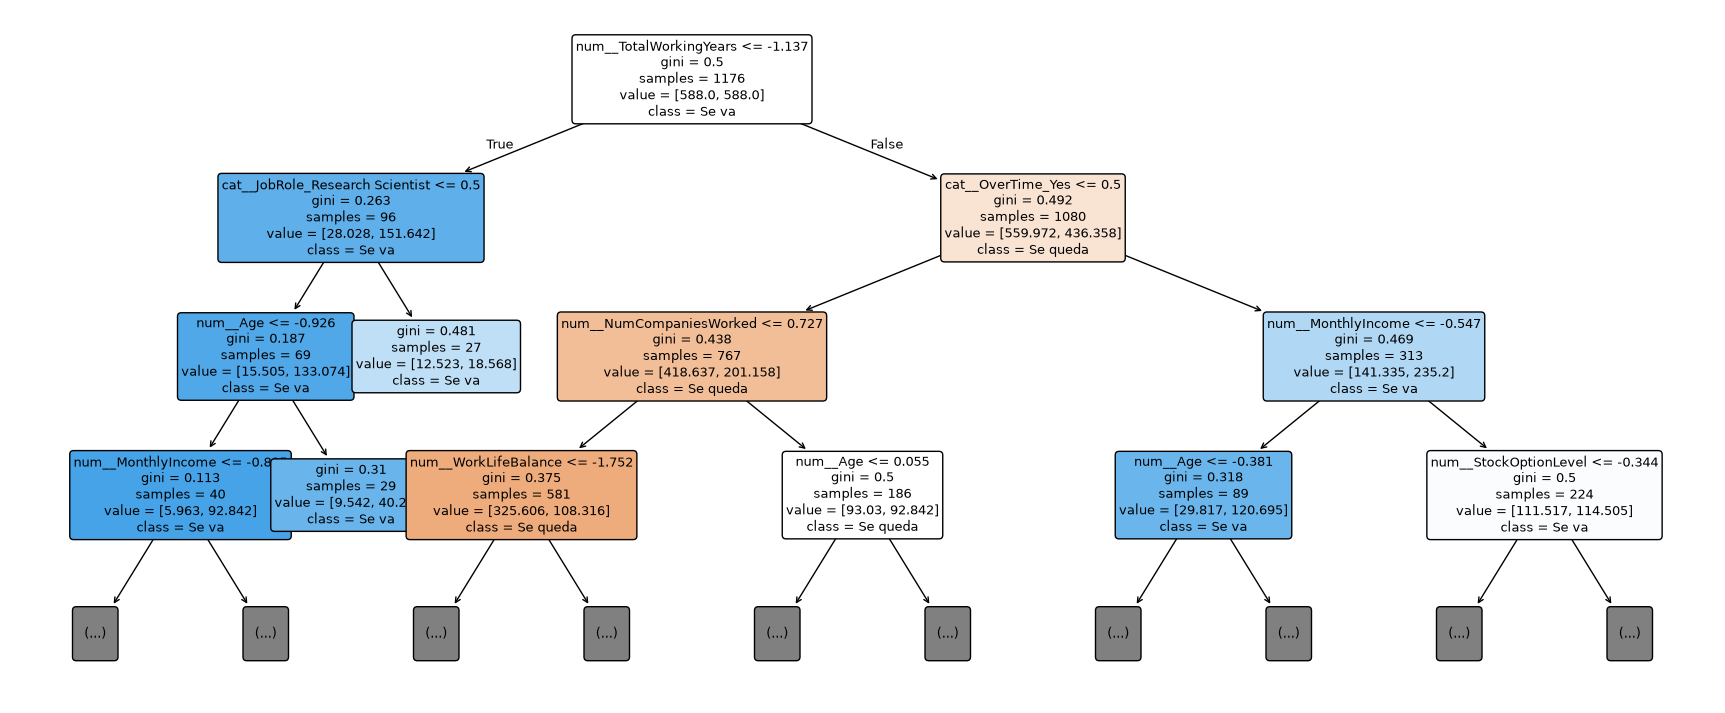

In [72]:
arbol = modelos["Árbol de decisión"]
plt.figure(figsize=(22, 9))
plot_tree(arbol.named_steps["clf"], feature_names=arbol.named_steps["prep"].get_feature_names_out(),
          class_names=["Se queda", "Se va"], filled=True, rounded=True, max_depth=3, fontsize=9)
plt.show()

#### Red neuronal (ANN) con TensorFlow 

Usamos TensorFlow para construir la red. Como scikit-learn no sabe trabajar directamente con un modelo de TensorFlow, creamos una clase envoltorio llamada "RedNeuronalKeras" que le da la interfaz de scikit-learn (fit, predict, predict_proba, get_params). Gracias a eso la red puede ir dentro del Pipeline, y también dentro de GridSearch y la validación cruzada, igual que los demás modelos.

**Arquitectura de la red:**
- Capas ocultas Dense con activación ReLU (el número de capas y neuronas es un hiperparámetro).
- Capa Dropout opcional, que apaga neuronas al azar durante el entrenamiento para reducir el sobreajuste.
- Capa de salida con una neurona sigmoide: devuelve la probabilidad de que el empleado se vaya.
- Pérdida binary_crossentropy y optimizador Adam.
- **Early stopping**: separamos el 20 % del entrenamiento (de forma estratificada) para vigilar la pérdida de validación y detenemos el entrenamiento cuando deja de mejorar.

**Hiperparámetros a ajustar:** capas, dropout y class_weight (con "balanced" el error de la clase minoritaria pesa más, lo que ayuda con el desbalance).

Para todo esto me ayuda de IA


In [77]:
import tensorflow as tf
from tensorflow import keras
from sklearn.base import BaseEstimator, ClassifierMixin

class RedNeuronalKeras(ClassifierMixin, BaseEstimator):
    """Red neuronal de Keras con la interfaz de scikit-learn, para usarla dentro de un Pipeline."""

    def __init__(self, capas=(32, 16), dropout=0.0, tasa_aprendizaje=0.001, epocas=100,
                 batch_size=32, paciencia=10, class_weight=None, random_state=42):
        self.capas = capas
        self.dropout = dropout
        self.tasa_aprendizaje = tasa_aprendizaje
        self.epocas = epocas
        self.batch_size = batch_size
        self.paciencia = paciencia
        self.class_weight = class_weight
        self.random_state = random_state

    def _construir(self, n_entradas):
        modelo = keras.Sequential()
        modelo.add(keras.Input(shape=(n_entradas,)))
        for neuronas in self.capas:
            modelo.add(keras.layers.Dense(neuronas, activation="relu"))
            if self.dropout > 0:
                modelo.add(keras.layers.Dropout(self.dropout))
        modelo.add(keras.layers.Dense(1, activation="sigmoid"))
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=self.tasa_aprendizaje),
                       loss="binary_crossentropy")
        return modelo

    def fit(self, X, y):
        keras.utils.set_random_seed(self.random_state)
        X = np.asarray(X, dtype="float32")
        y = np.asarray(y).astype("float32")
        self.classes_ = np.array([0, 1])

        # Pesos por clase para el desbalance
        pesos = None
        if self.class_weight == "balanced":
            n, n1 = len(y), y.sum()
            pesos = {0: n / (2 * (n - n1)), 1: n / (2 * n1)}

        # Parte del entrenamiento se reserva para vigilar el early stopping
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, stratify=y,
                                                    random_state=self.random_state)

        self.n_entradas_ = X.shape[1]
        self.model_ = self._construir(self.n_entradas_)
        parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.paciencia,
                                               restore_best_weights=True)
        historial = self.model_.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                                    epochs=self.epocas, batch_size=self.batch_size,
                                    class_weight=pesos, callbacks=[parada], verbose=0)
        self.historial_ = historial.history
        return self

    def predict_proba(self, X):
        p = self.model_.predict(np.asarray(X, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

    # Para poder guardar el Pipeline con joblib: se guardan los pesos y se reconstruye la red al cargar
    def __getstate__(self):
        estado = dict(super().__getstate__())
        if "model_" in estado:
            estado["pesos_"] = estado.pop("model_").get_weights()
        return estado

    def __setstate__(self, estado):
        estado = dict(estado)
        pesos = estado.pop("pesos_", None)
        super().__setstate__(estado)
        if pesos is not None:
            self.model_ = self._construir(self.n_entradas_)
            self.model_.set_weights(pesos)

I0000 00:00:1795774350.720529   79124 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795774351.138950   79124 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795774353.115883   79124 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [79]:
pipe_ann = Pipeline([
    ("prep", preprocesador()),
    ("clf", RedNeuronalKeras(random_state=RANDOM_STATE)),
])

rejilla_ann = {
    "clf__capas": [(16,), (32, 16)],
    "clf__dropout": [0.0, 0.3],
    "clf__class_weight": [None, "balanced"],
}

gs_ann = ajustar("ANN", pipe_ann, rejilla_ann)

E0000 00:00:1795774402.285935   79124 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Mejores parámetros: {'clf__capas': (16,), 'clf__class_weight': 'balanced', 'clf__dropout': 0.3}
f1 en validación cruzada: 0.555

===== ANN =====
Accuracy  train: 0.892 | prueba: 0.799
Precision: 0.412 | Recall: 0.596 | F1: 0.487
             pred: queda  pred: va
real: queda          207        40
real: va              19        28


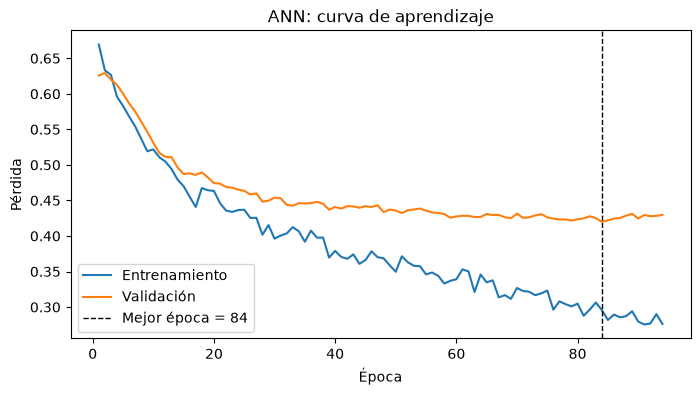

In [85]:
# La pérdida en el entrenamiento y en la validación. 
#Si la de validación empieza a subir mientras la de entrenamiento sigue bajando, 
#hay sobreajuste (el early stopping se detiene justo antes).
historial = pd.DataFrame(modelos["ANN"].named_steps["clf"].historial_)
mejor_epoca = int(historial["val_loss"].idxmin())

plt.figure(figsize=(8, 4))
plt.plot(historial.index + 1, historial["loss"], label="Entrenamiento")
plt.plot(historial.index + 1, historial["val_loss"], label="Validación")
plt.axvline(mejor_epoca + 1, color="k", ls="--", lw=1, label=f"Mejor época = {mejor_epoca + 1}")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("ANN: curva de aprendizaje")
plt.legend()
plt.show()

## CRISP-DM: Etapa 5

### Comparación de los modelos

Reunimos los resultados de todos los modelos. Observamos:

- score_cv: el F1 de la validación cruzada (con él elegimos el mejor modelo, porque no usa el conjunto de prueba)
- f1, recall y precision: el desempeño en el conjunto de prueba para la clase "renucia".
- brecha: la diferencia entre la exactitud en entrenamiento y en prueba.

In [86]:
tabla = pd.DataFrame(resultados).T
tabla["brecha"] = tabla["acc_train"] - tabla["acc_test"]
tabla = tabla.sort_values("score_cv", ascending=False)
tabla.round(3)

,score_cv,acc_train,acc_test,precision,recall,f1,brecha
ANN,0.555,0.892,0.799,0.412,0.596,0.487,0.093
Árbol de decisión,0.414,0.763,0.643,0.236,0.553,0.331,0.120
K-NN,0.204,0.871,0.844,0.533,0.170,0.258,0.027


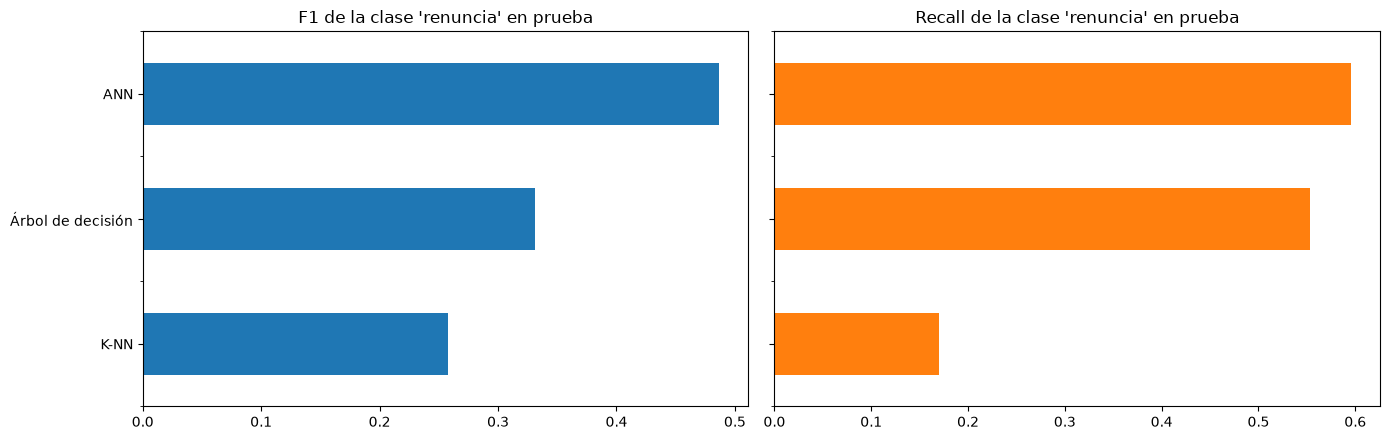

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
orden = tabla.sort_values("f1").index
tabla.loc[orden, "f1"].plot(kind="barh", ax=axes[0])
axes[0].set_title("F1 de la clase 'renuncia' en prueba")
tabla.loc[orden, "recall"].plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("Recall de la clase 'renuncia' en prueba")
plt.tight_layout()
plt.show()

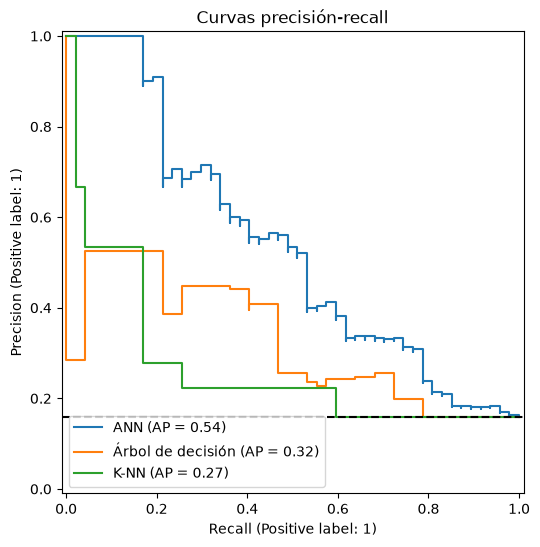

In [89]:
plt.figure(figsize=(8, 6))
for nombre in tabla.index:
    PrecisionRecallDisplay.from_predictions(y_test, puntuaciones(modelos[nombre], X_test), name=nombre, ax=plt.gca())
plt.axhline(y_test.mean(), color="k", ls="--")
plt.title("Curvas precisión-recall")
plt.show()

#### ¿Qué modelo elegir?

Ya con la información del rendimiento de cada uno de los modelos, podemos decidir que la red neuronal tiene el mejor rendimiento y sería el modelo que elegiría para resolver esto, sin embargo estoy seguro que hay más modelos que quiza puedan obtener un mejor rendimiento o lgo muy similar, pero ser más simple que la red neuronal, de igual forma los hiperparámetros que elegí, no los sometí al GridSearch (la función de perdida y el optimizador), quizas no sean los ideales, use algo que fuera un tanto diferente a lo de clase para empezar a ver cómo las redes neuronales se comportan con otros hiperparámetros.

Menciono esto porque al menos con mi capacidad de computo (Un procesador de 4 nucleos y 12 GB de RAM), la red neuronal y la busquda de los hiperparámetros si conllevó una buena cantidad de tiempo, mientras que el resto aún usando Gridsearch, se mantuvieron dentro de los dos minutos.

#### ¿Y si queremos identificar las causas?

Supongamos que se implementa la red neuronal y empezamos a usarla dento del departamento de recursos humanos, pero muy temprano nos daremos cuenta que podremos hacer un pronóstico de algún empleado que esté próximo a renunciar, pero ¿Nustro modelo nos da información?, y en general las redes neuronales son algo "abstractas" con eso; mi sugerencia es que si queremos identificar causas, lo más ideal sería usar el ärbol de decisiones, ya que nos da información sobre que criterios usa en cada segmentación, quizas no tiene el mismo rendimiento que la ANN, pero si tiene esta otra cualidad, y de esto era lo que en un inicio quería retratar en mi proyecto, hacer la predicción de los empleados que que renuncian o permanencen en la compañía es algo que ya se ha hecho muchas veces y está muy bien documentado en internet, sin embargo mi idea es ejemplificar que no existe el modelo perfecto, sólo existe el que mejor se ajusta a las necesidades.

Incluso para esta última pregunta pudimos hacer uso de la estadística descriptiva y con gráficos y un poco de interpretación ya es un producto que perfectamente se puede presentar a un administrativo de la empresa.

A mi parecer es más relevante saber que es lo que motiva a un empleado a abandonar la compañía que saber qué empleados van a irse, es preferible mitigar la rotación del personal a base de acabar con las causas, esto ayuda más a una compañía y resultará mucho más barato en el largo plazo.



## Conclusiones

- El dataset original es de bsatante buena calidad, no presenta nulos o valores duplicados, el único inconveniente que presenta es que está desbalanceado.
- Por el hecho de estar desbalanceado usar accurracy como métrica no es buena idea, este proyecto me da una mejor noción de como tratar con este tipo de datasets.

## Anexo: Análisis Estadśtico breve

### Distribución de las numéricas continuas

Con esto podremos apreciar si existe asimetría, ver la dispersión y la tendencia central

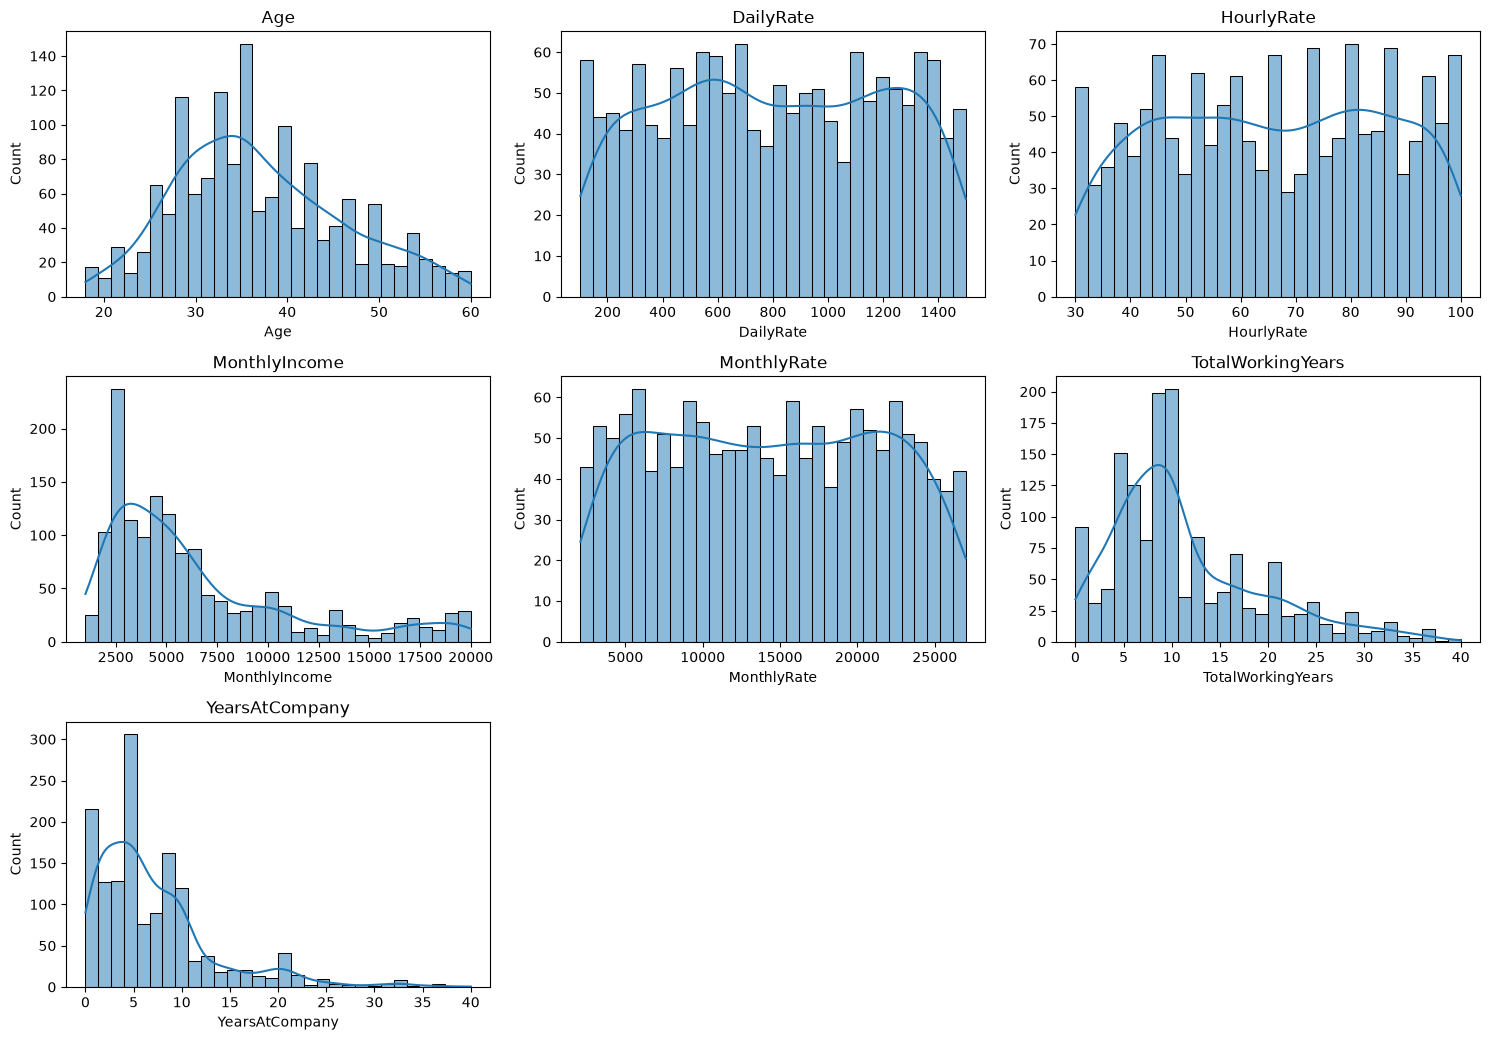

In [92]:
ncols = 3
nrows = 3
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.histplot(X[c], bins=30, kde=True, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(cont_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### ¿Cómo se comporta cada variable frente attrition?

Ahora comparamos cada variable contra la deserción. En lugar de contar cuántos empleados se van en cada grupo, calculamos la tasa de deserción (el porcentaje que se va dentro de cada grupo)

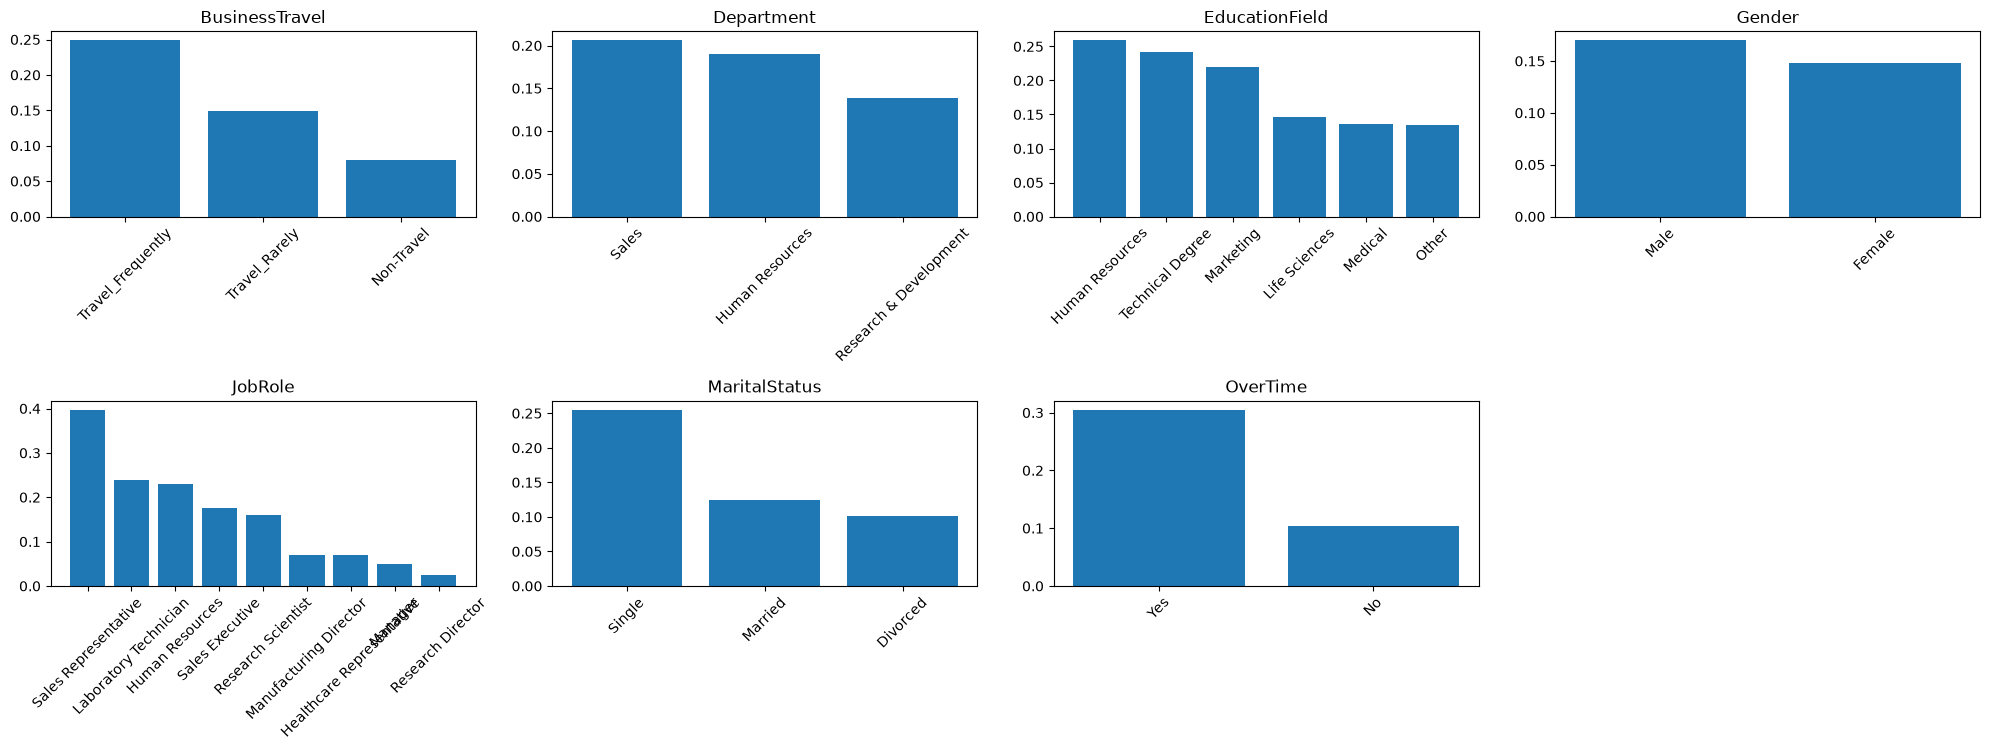

In [95]:
df_eda = X.copy()
df_eda["Attrition"] = y
tasa_global = y.mean()
def graficar_tasas(columnas, ordenar, ncols=4):
    nrows = int(np.ceil(len(columnas) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
    for ax, c in zip(axes.ravel(), columnas):
        tasa = df_eda.groupby(c)["Attrition"].mean()
        if ordenar:
            tasa = tasa.sort_values(ascending=False)
        ax.bar(tasa.index.astype(str), tasa.values)
        ax.set_title(c)
        ax.tick_params(axis="x", rotation=45 if ordenar else 0)
    for ax in axes.ravel()[len(columnas):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

graficar_tasas(cat_cols, ordenar=True)

Ahora con las discretas

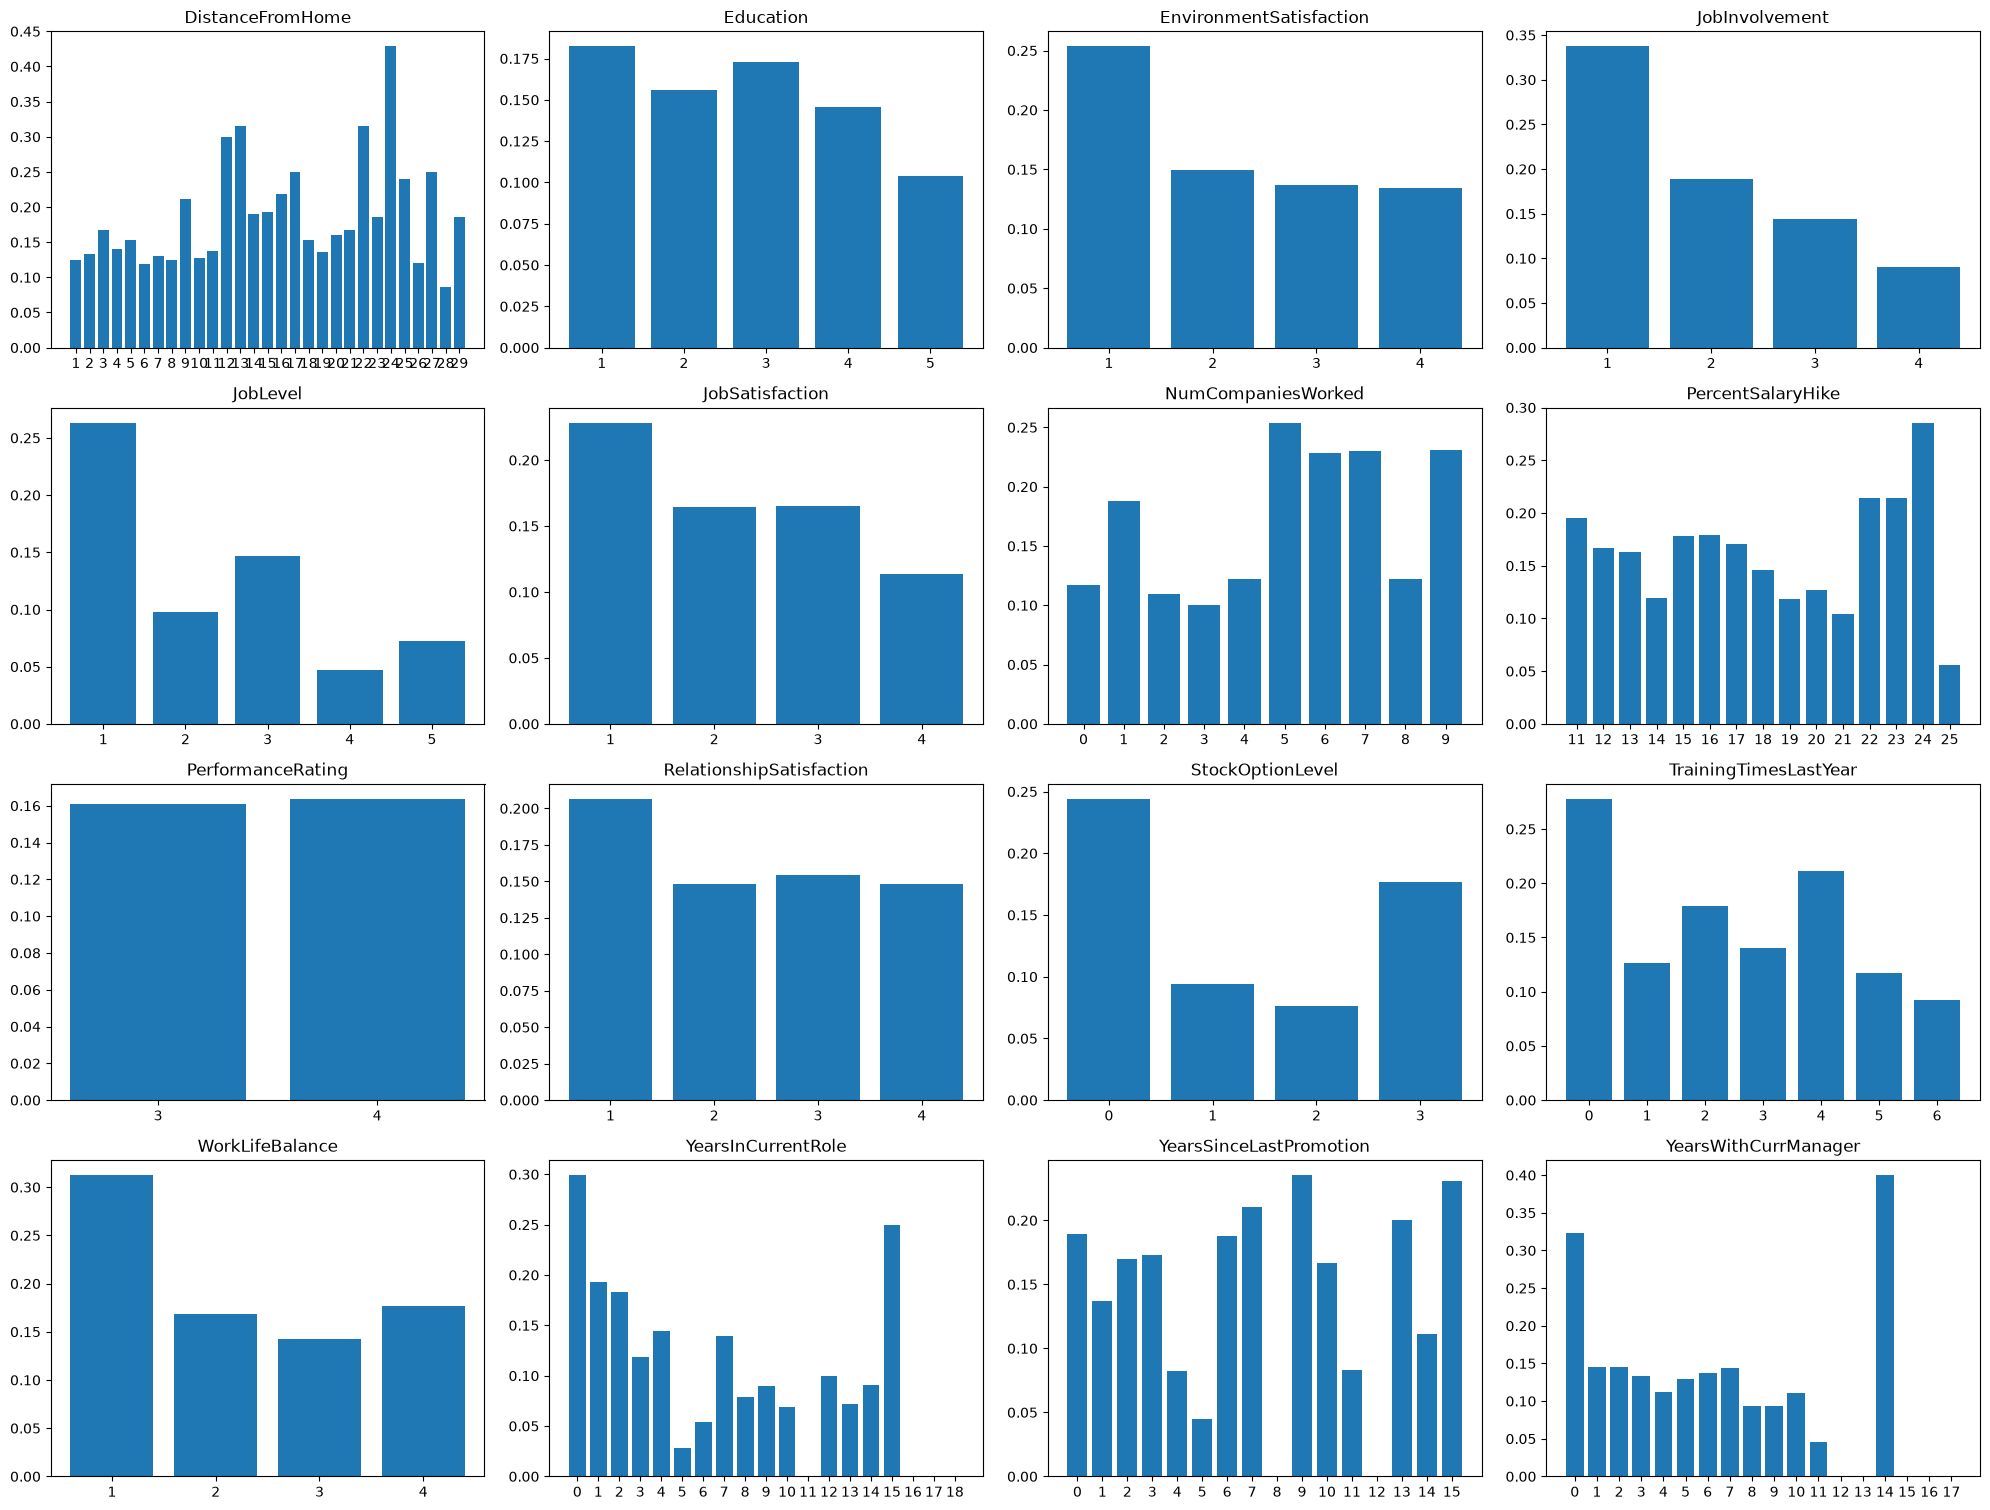

In [96]:
graficar_tasas(disc_cols, ordenar=False)

#### Correlación entre variables

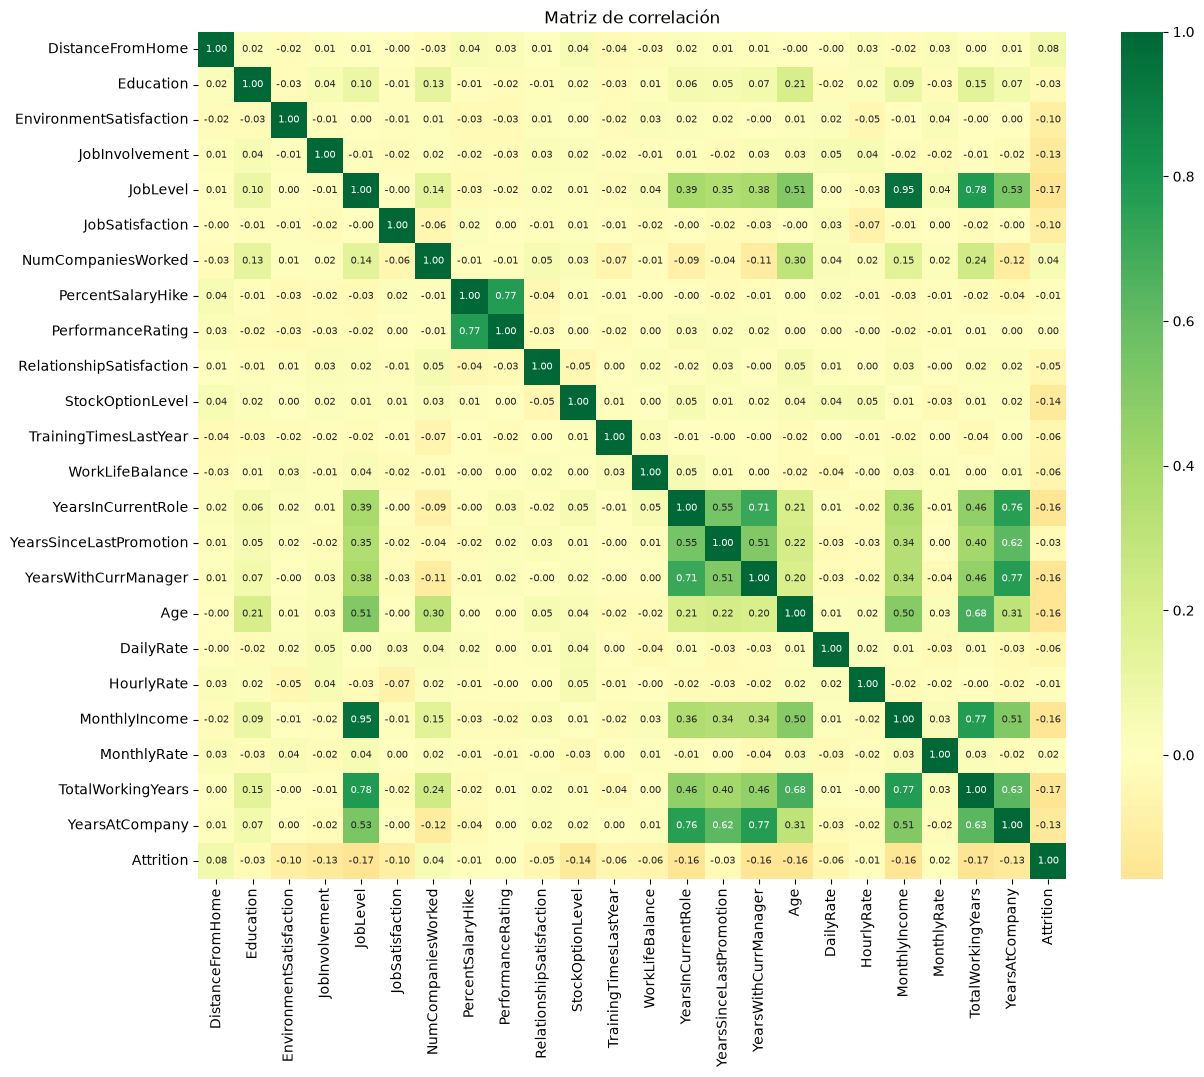

In [98]:
corr = df_eda[num_cols + ["Attrition"]].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.show()

#### Correlación con attrition

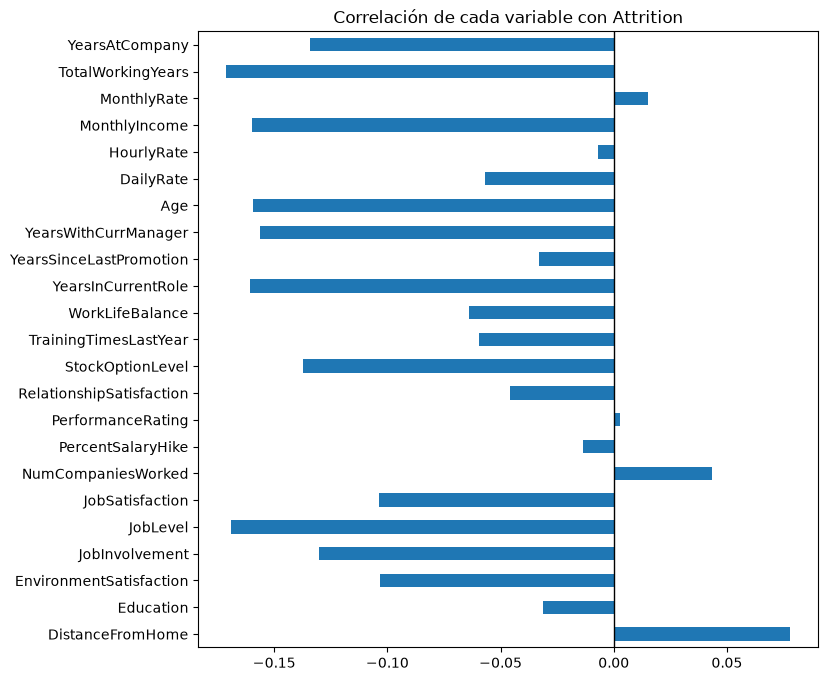

In [99]:
corr["Attrition"].drop("Attrition").plot(kind="barh", figsize=(8, 8))
plt.axvline(0, color="k", lw=1)
plt.title("Correlación de cada variable con Attrition")
plt.show()

### Observaciones del análisis

Con los gráficos anteriores podemos identificar el perfil de mayor riesgo de deserción:

- Los empleados que hacen horas extra se van mucho más que los que no.
- Los niveles bajos en JobLevel, MonthlyIncome, TotalWorkingYears y YearsAtCompany (empleados jóvenes, de menor puesto y poca antigüedad) tienen más deserción.
- Los solteros se van más que los casados y divorciados.
- Quienes viajan frecuentemente tienen mayor tasa de deserción.
- Los empleados sin stock options (StockOptionLevel = 0) se van más.

MonthlyIncome, JobLevel y TotalWorkingYears están muy correlacionadas entre sí. 